# LeetCode #297: Serialize and Deserialize Binary Tree

https://leetcode.com/problems/serialize-and-deserialize-binary-tree/

## Two ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Level by level with a queue** | $O(n)$ | $O(n)$ | LeetCode's own format. Needs a queue on both sides. |
| **Root-first walk with null markers ★** | $O(n)$ | $O(n)$ | Two short recursive functions that mirror each other. |

`n` is the number of nodes. $O(n)$ means **the work grows with the number of nodes**: every node, and
every empty spot under a node, is written once and read once, so 10,000 nodes is about 20,000 tokens.
The space is the string itself, which can't be smaller than the tree it describes.

**Serialize** means turning the tree into a string you could save or send. **Deserialize** means
rebuilding the exact same tree from that string. You choose the format; the only rule is that the round
trip gives back the original.

## Understanding the methods

### Level by level with a queue

Write the root, then its two children, then their children, row by row, with a marker for every missing
child. Reading back uses a queue of nodes still waiting for their children. Correct and familiar, but
both directions need the queue bookkeeping.

### Optimal: root-first walk with null markers ★ (the one coded below)

Write a node's value, then everything in its left subtree, then everything in its right subtree (a
**preorder** walk), and write `null` wherever a child is missing. Because every node has exactly two
child slots and every slot is written down, the reader always knows where one subtree stops and the
next starts. It reads the tokens in the same order, building a node for each value and stopping a
branch at each `null`.

**Why this beats the level-by-level version:** both are $O(n)$, but here the reader is the writer run
backwards, two recursive functions with the same shape, and no queue on either side.

**Constraints:**
* The number of nodes is in the range `[0, 10^4]`
* `-1000 <= Node.val <= 1000`


## Explain Like I'm a Newbie

### What the question is actually asking

Write a function that turns a tree into a string, and a second function that turns that string back
into the same tree: same values, same shape. You invent the format.

### The one idea you need: write down the gaps, not just the values

Listing the values alone loses the shape. These two trees both list as `1, 2`:

```
   1          1
  /            \
 2              2
```

So the string has to say where the empty spots are. Walk the tree root first, then the left subtree,
then the right subtree, and every time a child is missing, write `null`:

```
   1
  / \        1, 2, null, null, 3, 4, null, null, 5, null, null
 2   3
    / \
   4   5
```

Now reading back is mechanical. Take a token. If it's a number, make a node, then build its left
subtree from the tokens that follow, then its right subtree. If it's `null`, that slot is empty and you
go back up. Every node has exactly two slots and every slot was written down, so you always know when a
subtree is finished. No guessing.

Writing the root *first* matters too. The reader meets each node's value before anything underneath it,
so it can create the node straight away and then fill in its children. If the root came in the middle,
the reader wouldn't know which value was the root.

### What that means in code

Both functions are recursive and have the same shape. The writer appends a value, recurses left, recurses
right, and appends `null` for an empty node. The reader takes the next token, returns nothing for `null`,
otherwise makes a node and fills its left child, then its right child.

The reader's position in the token list must be **shared** by every call. When the left subtree finishes,
the right subtree has to start at the very next token.

### Mistakes people make the first time

1. **Gluing tokens together with no separator and reading one character at a time.** This passes both of
   LeetCode's samples, `[1,2,3,null,null,4,5]` and `[]`, because every value there is one digit. Then
   `[12]` crashes: the reader takes `1`, then `2`, and runs out of string. A negative value like `-1`
   crashes on the `-`. Use a separator between tokens.
2. **Skipping the nulls.** The shape is gone and the two trees above become the same string.
3. **Giving each recursive call its own copy of the position.** The right subtree then re-reads the
   tokens the left subtree already used.
4. **Writing left-then-right but reading right-then-left.** The tree comes back mirrored.

### Things worth knowing

More than half the tokens are `null`: a tree with `n` nodes has `n + 1` empty slots. That's the price
of a format this simple. The recursion goes as deep as the tree is tall, so a 10,000-node chain is
10,000 nested calls, past Python's default limit of 1,000.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "A traversal on its own loses the shape, so I'll write a preorder walk with an explicit `null` for every empty child. Every node has two slots and every slot is in the string, so the reader always knows where a subtree ends. Reading is the same walk run backwards: one token per call, with a shared cursor. That's n values plus n + 1 nulls, O(n) both ways. The costs are a string that's mostly nulls, and recursion as deep as the tree."

Format, reason, cost, weak spots. That's the answer I'm hoping to reconstruct over the next half hour.

---

### I slide the problem across the table

I write the class signature, `serialize(root)` and `deserialize(data)`, and draw `[1,2,3,null,null,4,5]`.

> **You:** "Is the format mine, or does it have to match LeetCode's level-order string?"

**"Yours. The only test is that deserializing what you serialized gives the same tree."** That's the clarifier that matters in a design problem: it tells you how much freedom you have, and it means you get to pick the format that makes the code simplest.

> **You:** "What's in the nodes? Negative numbers, more than one digit?"

**"Integers from -1000 to 1000, up to 10,000 nodes, and zero nodes is allowed."** That answer quietly decides your separator. Hold onto it.

---

### Now tell me what's actually hard about it

> **You:** "Writing the values out is easy. Getting the shape back is the problem. The tree with 2 as a left child and the tree with 2 as a right child both have preorder `1, 2`. So any format that's only the values is ambiguous."

> **You:** "The fix is to write down the gaps. If I put `null` in every empty child slot, then when I'm reading and I've finished a node's left slot and its right slot, that subtree is done. The string marks its own boundaries."

That's the difficulty first and the trick second, and I watched it come out of a two-node counterexample you built. I'll sometimes push: "why preorder and not inorder?" The answer I want: preorder puts the root first, so the reader can create the node before it reads anything about its children. Inorder puts the root in the middle, and the reader wouldn't know which value is the root.

---

### Agree the format before the methods

For a design problem I want the data structure on the board before any method. Here the structure is the string:

> **You:** "Tokens separated by commas. Each token is either an integer or the word `null`. Order is preorder: node, then left subtree, then right subtree. Commas because values can be negative and up to four characters long, so I can't read one character at a time."

That's the sentence I was waiting for when I told you the value range. If you skip it, I'll ask what `[12]` turns into.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "`serialize` is a recursive walk that appends a token per call. A tree with n nodes has n + 1 empty slots, so that's 2n + 1 calls and 2n + 1 tokens. `deserialize` splits the string and runs the mirror-image recursion, consuming exactly one token per call, so also 2n + 1 calls. O(n) each way. Space is O(n) for the string and token list, plus the call stack, which is as deep as the tree."

Derived from counting slots, not announced. Good.

---

### Now whiteboard it

```
def serialize(root):
    result = []
    def dfs(node):
        if not node:
            result.append('null')
            return
        result.append(str(node.val))
        dfs(node.left)
        dfs(node.right)
    dfs(root)
    return ','.join(result)
```

> **You:** "The `null` branch is the whole point. Without it, this is a plain preorder and it can't be undone."

```
def deserialize(data):
    tokens = iter(data.split(','))
    def dfs():
        val = next(tokens)
        if val == 'null':
            return None
        node = TreeNode(int(val))
        node.left = dfs()
        node.right = dfs()
        return node
    return dfs()
```

> **You:** "One iterator, shared by every call. When the left subtree's calls return, the iterator is sitting exactly on the first token of the right subtree. If I'd passed an index by value, the right side would start reading where the left side began."

> **You:** "And left before right, the same order as the writer. Swap them here and the tree comes back mirrored."

Those are the two lines people get wrong. I'd rather hear the reason than see the code alone.

---

### Walk me through it before you say you're done

> **You:** "Your tree serializes to `1,2,null,null,3,4,null,null,5,null,null`, eleven tokens for five nodes. Reading: 1 becomes the root. Its left call reads 2, whose two calls read `null`, `null`, so 2 is a leaf. Back at the root, the right call reads 3. 3's left reads 4, then `null`, `null`. 3's right reads 5, then `null`, `null`. Every token used exactly once, and the tree matches."

> **You:** "Zero nodes, which you said was allowed: the root is empty, so the string is just `null`, and the reader returns `None` on the first token."

---

### Then tell me where it breaks, before I ask

> **You:** "Time is optimal: I have to write every value. Two honest costs. First, depth. Both functions recurse as deep as the tree is tall, and a 10,000-node chain is 10,000 nested calls, past Python's default of 1,000. If that matters, I'd switch to the level-by-level format with a queue, which never recurses. Second, size. n + 1 of the 2n + 1 tokens are `null`. If the string were going over a network, I'd drop trailing nulls the way LeetCode does, or move to a binary format with a bit per slot."

I like that you separated them. Depth is a correctness problem in Python; size is a cost the caller might or might not care about.

Then I'll ask the follow-up I always ask: "what if I told you it's a binary search tree?"

> **You:** "Then I don't need the nulls at all. In a BST the values themselves say where everything goes: after the root, the next values smaller than it are its left subtree and the rest are its right. So I'd write plain preorder and rebuild by passing a (low, high) range down, the same way you'd validate a BST. The string shrinks by more than half."

That's the generalisation I was hoping for. It shows the nulls are there because a general tree carries no ordering, not out of habit. Someone who memorised this solution usually keeps the nulls for the BST version too, and can't say why they're no longer needed.

And if I ask whether the reader could ever run out of tokens or have some left over:

> **You:** "Not on a string my own writer produced. Each value token opens two slots and each `null` fills one, and the writer emitted exactly one token per slot, so the reader closes the last slot on the last token. On a hand-edited string all bets are off, and `next` would raise. If the input could be untrusted I'd validate it rather than trust that count."

---

### What would worry me

Reading the string one character at a time because the example only had single digits. Using a separate index variable that each recursive call copies. Writing nulls only for leaves, which breaks on a node with one child. And jumping into level-order code with a queue before you've said why the plain values aren't enough.


## Solutions

All four write a preorder walk with `null` for every empty slot, and read it back with the same walk and one shared position in the token list.

### C#

`serialize` puts a comma after every token, including the last, so `Split` leaves an empty final piece. That's why `deserialize` treats `""` like `"null"`.


In [ ]:
public class Codec {
    public string serialize(TreeNode root) {
        var sb = new System.Text.StringBuilder();
        // Root first, then left subtree, then right subtree (preorder)
        void dfs(TreeNode node) {
            // Write a marker for every empty child slot. Without it, [1,2] and
            // [1,null,2] would produce the same string and the shape would be lost.
            if (node == null) { sb.Append("null,"); return; }
            // The comma separates tokens, so "-12" is read as one value, not three characters
            sb.Append(node.val).Append(',');
            dfs(node.left);
            dfs(node.right);
        }
        dfs(root);
        return sb.ToString();
    }

    public TreeNode deserialize(string data) {
        // One shared queue: every call takes the NEXT token, so when the left
        // subtree is finished, the right subtree starts exactly where it stopped
        var tokens = new Queue<string>(data.Split(','));
        TreeNode dfs() {
            string val = tokens.Dequeue();
            // "" is the empty piece after the trailing comma
            if (val == "null" || val == "") return null;
            var node = new TreeNode(int.Parse(val));
            // Same order as serialize: left first, then right
            node.left = dfs();
            node.right = dfs();
            return node;
        }
        return dfs();
    }
}

### Python

`iter(...)` plus `next(tokens)` is the shared position: the iterator remembers where it is, so every nested call picks up the next token without an index being passed around.


In [ ]:
class Codec:
    def serialize(self, root) -> str:
        result = []
        # Root first, then left subtree, then right subtree (preorder)
        def dfs(node):
            # Write a marker for every empty child slot. Without it, [1,2] and
            # [1,null,2] would produce the same string and the shape would be lost.
            if not node:
                result.append('null')
                return
            result.append(str(node.val))
            dfs(node.left)
            dfs(node.right)
        dfs(root)
        # Commas separate tokens, so "-12" is read back as one value, not three characters
        return ','.join(result)

    def deserialize(self, data: str):
        # One shared iterator: every call takes the NEXT token, so when the left
        # subtree is finished, the right subtree starts exactly where it stopped
        tokens = iter(data.split(','))
        def dfs():
            val = next(tokens)
            if val == 'null':
                return None   # an empty slot: this branch stops here
            node = TreeNode(int(val))
            # Same order as serialize: left first, then right
            node.left = dfs()
            node.right = dfs()
            return node
        return dfs()

### Go

`var dfs func(...)` is declared before it's assigned so the function literal can call itself. `idx` lives outside `dfs`, so every call moves the same position forward.


In [ ]:
import (
    "strconv"
    "strings"
)

type Codec struct{}

func Constructor() Codec { return Codec{} }

func (c *Codec) serialize(root *TreeNode) string {
    var sb strings.Builder
    // Root first, then left subtree, then right subtree (preorder)
    var dfs func(*TreeNode)
    dfs = func(node *TreeNode) {
        // Write a marker for every empty child slot. Without it, [1,2] and
        // [1,null,2] would produce the same string and the shape would be lost.
        if node == nil {
            sb.WriteString("null,")
            return
        }
        sb.WriteString(strconv.Itoa(node.Val))
        sb.WriteByte(',')   // separator, so "-12" is read as one value
        dfs(node.Left)
        dfs(node.Right)
    }
    dfs(root)
    return sb.String()
}

func (c *Codec) deserialize(data string) *TreeNode {
    tokens := strings.Split(data, ",")
    // One shared position: every call takes the NEXT token, so when the left
    // subtree is finished, the right subtree starts exactly where it stopped
    idx := 0
    var dfs func() *TreeNode
    dfs = func() *TreeNode {
        // "" is the empty piece after the trailing comma
        if idx >= len(tokens) || tokens[idx] == "null" || tokens[idx] == "" {
            idx++
            return nil
        }
        val, _ := strconv.Atoi(tokens[idx])
        idx++
        node := &TreeNode{Val: val}
        // Same order as serialize: left first, then right
        node.Left = dfs()
        node.Right = dfs()
        return node
    }
    return dfs()
}

### Rust

A nested `fn` can't see the surrounding variables (unlike a closure), so the token list and position are passed in, the position as `&mut usize` so every call advances the same counter.


In [ ]:
use std::cell::RefCell;
use std::rc::Rc;

struct Codec;

impl Codec {
    fn new() -> Self { Codec }

    fn serialize(&self, root: Option<Rc<RefCell<TreeNode>>>) -> String {
        let mut result = Vec::new();
        // Root first, then left subtree, then right subtree (preorder)
        fn dfs(node: &Option<Rc<RefCell<TreeNode>>>, result: &mut Vec<String>) {
            match node {
                // Write a marker for every empty child slot. Without it, [1,2] and
                // [1,null,2] would produce the same string and the shape would be lost.
                None => result.push("null".to_string()),
                Some(n) => {
                    let n = n.borrow();
                    result.push(n.val.to_string());
                    dfs(&n.left, result);
                    dfs(&n.right, result);
                }
            }
        }
        dfs(&root, &mut result);
        // Commas separate tokens, so "-12" is read back as one value
        result.join(",")
    }

    fn deserialize(&self, data: String) -> Option<Rc<RefCell<TreeNode>>> {
        let tokens: Vec<&str> = data.split(',').collect();
        // One shared position (passed as &mut): every call takes the NEXT token, so when
        // the left subtree is finished, the right subtree starts exactly where it stopped
        let mut idx = 0;
        fn dfs<'a>(tokens: &[&'a str], idx: &mut usize) -> Option<Rc<RefCell<TreeNode>>> {
            if *idx >= tokens.len() || tokens[*idx] == "null" {
                *idx += 1;
                return None;   // an empty slot: this branch stops here
            }
            let val: i32 = tokens[*idx].parse().unwrap();
            *idx += 1;
            let node = Rc::new(RefCell::new(TreeNode::new(val)));
            // Same order as serialize: left first, then right
            node.borrow_mut().left = dfs(tokens, idx);
            node.borrow_mut().right = dfs(tokens, idx);
            Some(node)
        }
        dfs(&tokens, &mut idx)
    }
}

## Example Scenarios

### 1. Common Case — Right Subtree Has Children
**Input:** `root = [1,2,3,null,null,4,5]`

Write each node, then its left side, then its right side, with `null` in every empty slot. Five nodes
give eleven tokens, `"1,2,null,null,3,4,null,null,5,null,null"`, and reading them in the same order
rebuilds the identical tree. **Output:** the same tree

### 2. Slightly Complex — Unbalanced Shape
**Input:** `root = [5,3,8,1,null,null,9]`

3 has only a left child and 8 only a right child. The `null`s record which side is missing, so the shape
survives: `"5,3,1,null,null,null,8,null,9,null,null"`. **Output:** the same tree

### 3. Edge Case: Time Factor — Full Tree
**Input:** `root = [1,2,3,4,5,6,7]`

Every node and every empty slot is written once and read once: 7 values plus 8 `null`s, 15 calls each
way. Any 7-node tree costs the same 15 calls, so this shape is a fair picture of $O(n)$ rather than a
worse case: `"1,2,4,null,null,5,null,null,3,6,null,null,7,null,null"`. **Output:** the same tree

### 4. Edge Case: Space Factor — Left-Skewed Chain
**Input:** `root = [1,2,null,3]`

Each node waits for the one below it, so the recursion is as deep as the tree is tall, the most stack
this solution uses. At 10,000 nodes that's past Python's default limit of 1,000. The string is
`"1,2,3,null,null,null,null"`. **Output:** the same tree

### 5. Almost-Impossible but Plausible — Empty Tree
**Input:** `root = []`

Zero nodes is allowed. The root slot is empty, so the whole string is `"null"`, and the reader returns an
empty tree on its first token. **Output:** `[]`


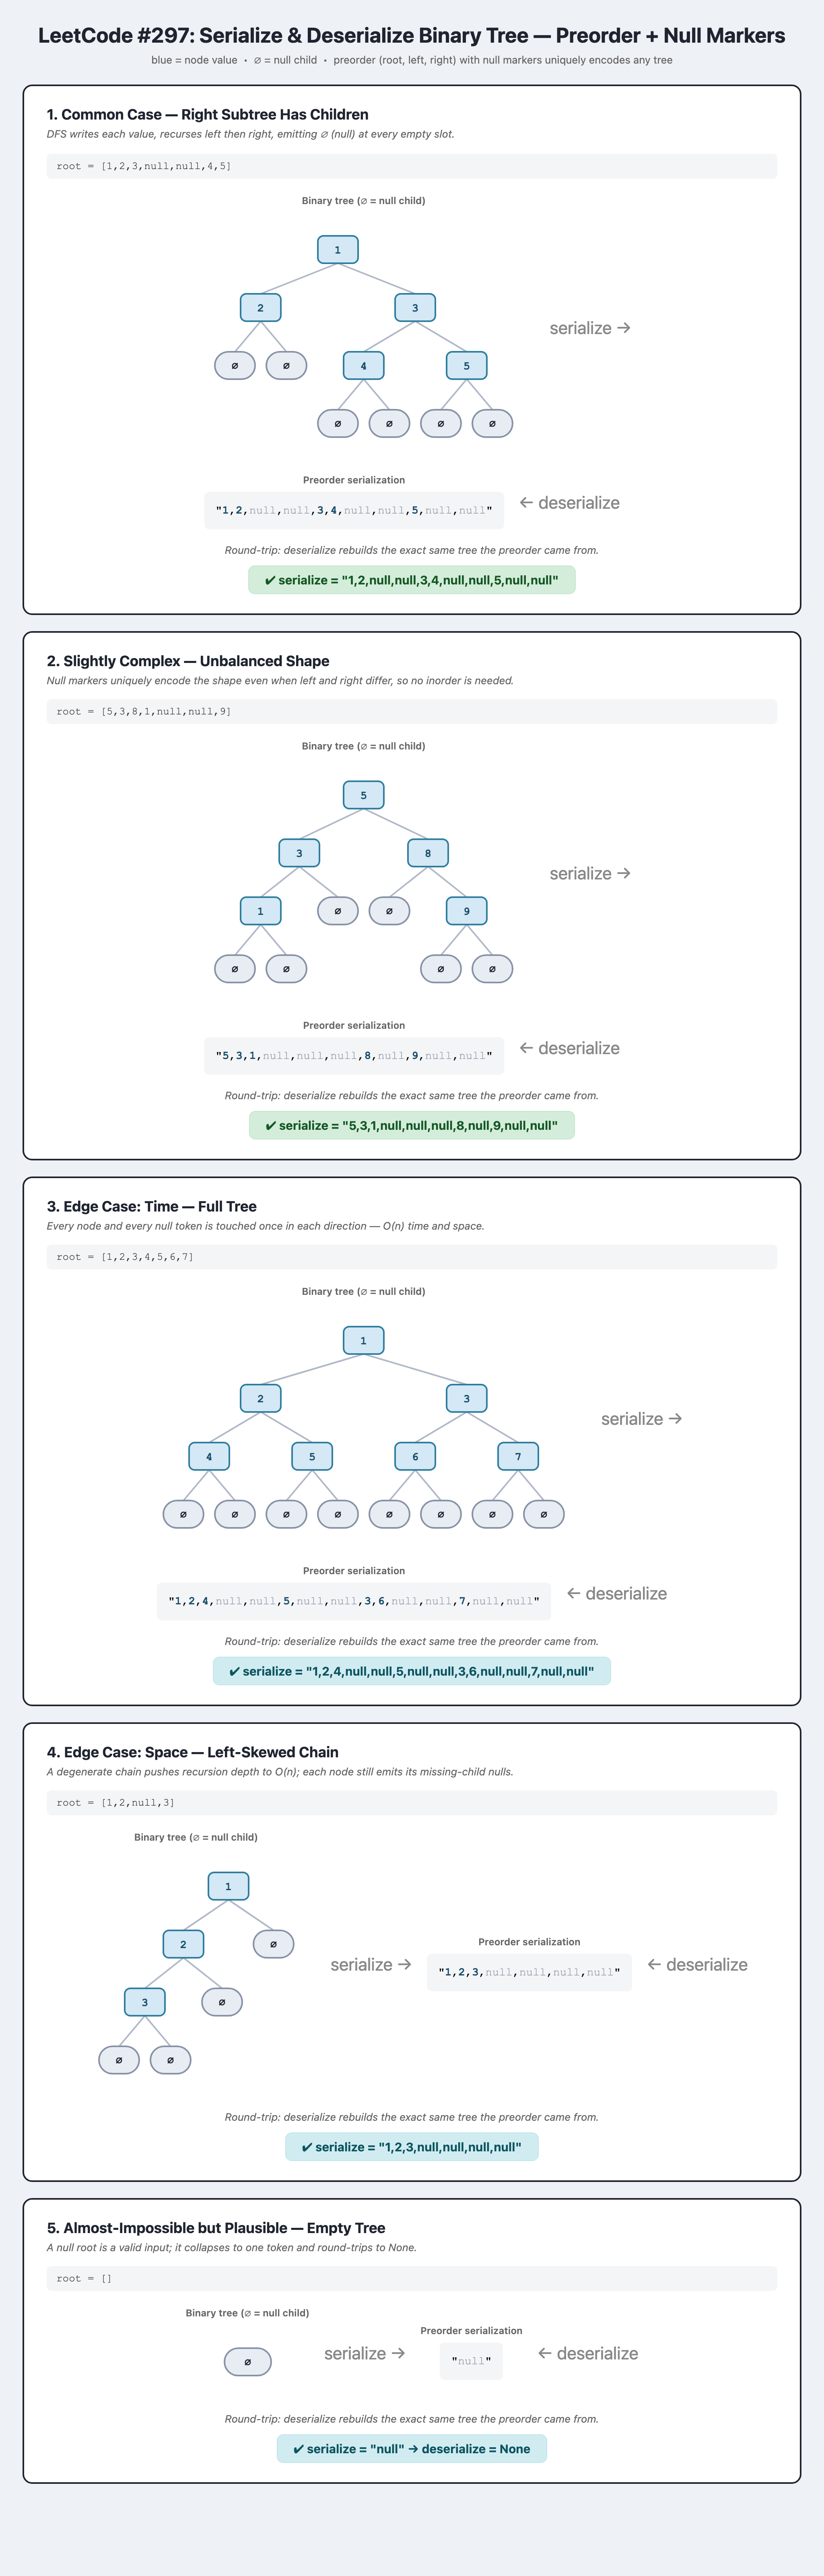

## Watch It Run

*Watch the reader reach token 4: the calls that built 2 used tokens 1 to 3, so the shared cursor is already on the 3, the root's right child.*

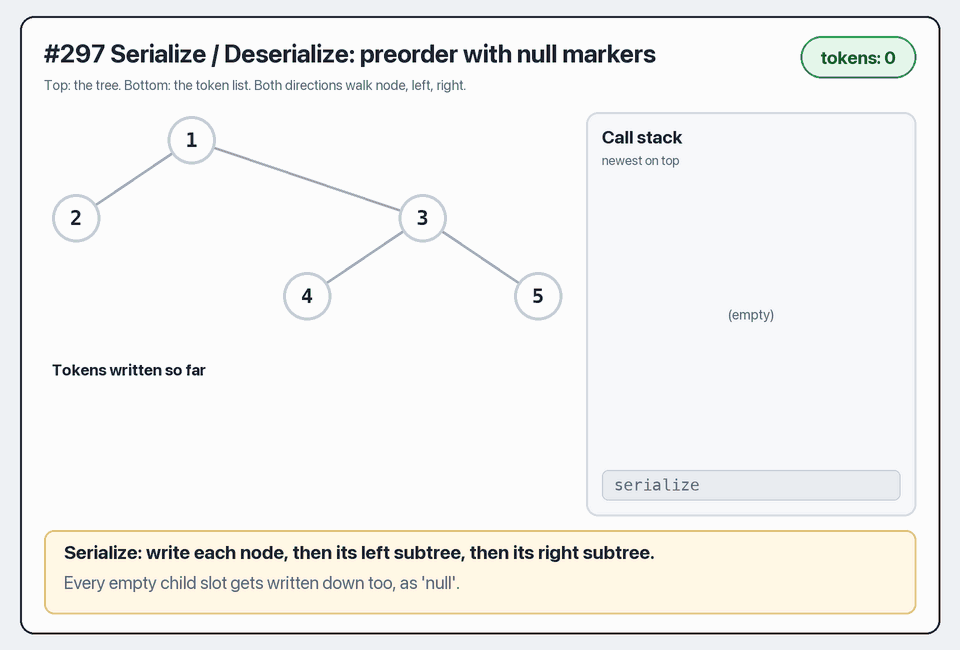

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0297.html)**